<a href="https://colab.research.google.com/github/karizma-pinkney/cms-dimuon-analysis/blob/main/CMS_Dimuon_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconstructing Particle Masses from CMS Open Data

Author: Karizma Pinkney

Independent educational project using public CMS data from CERN. Not an official CMS collaboration project.

Goal: Load a dataset of muon pairs, plot their invariant mass, and calculate those masses myself from energy to momentum.

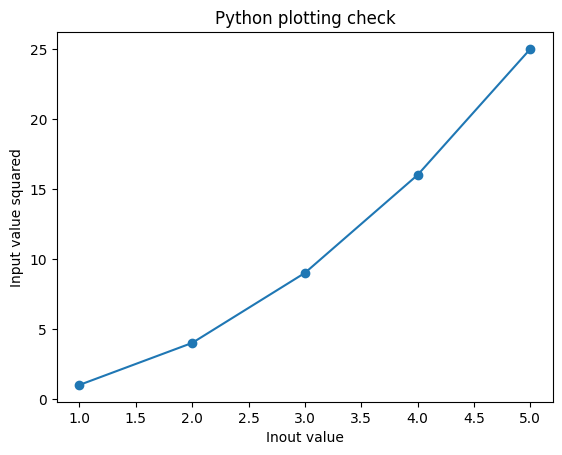

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

values = np.array([1,2,3,4,5])

plt.plot(values, values**2,
         marker="o")
plt.xlabel("Inout value")
plt.ylabel("Input value squared")
plt.title("Python plotting check")
plt.show()

In [14]:
import pandas as pd
import requests

url = "http://opendata.cern.ch/record/545/files/Dimuon_DoubleMu.csv"

response = requests.get(url)
with open("Dimuon_DoubleMu.csv", "wb") as f:
  f.write(response.content)

data = pd.read_csv("Dimuon_DoubleMu.csv")

print("Rows in the files:", len(data))
print()
data.head()

Rows in the files: 100000



,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,165617,74601703,G,9.6987,-9.5104,0.3662,1.8633,9.5175,0.1945,3.1031,...,G,9.7633,7.3277,-1.1524,6.3473,7.4178,0.7756,-0.1560,1,17.4922
1,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,...,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1,11.5534
2,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,...,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1,9.1636
3,165617,75660978,G,7.0427,-6.3268,-0.2685,3.0802,6.3325,0.4690,-3.0992,...,G,5.5857,4.4748,0.8489,-3.2319,4.5546,-0.6605,0.1875,1,12.4774
4,165617,75947690,G,7.2751,0.1030,-5.5331,-4.7212,5.5340,-0.7736,-1.5522,...,G,7.3181,-0.3988,6.9408,2.2825,6.9523,0.3227,1.6282,1,14.3159


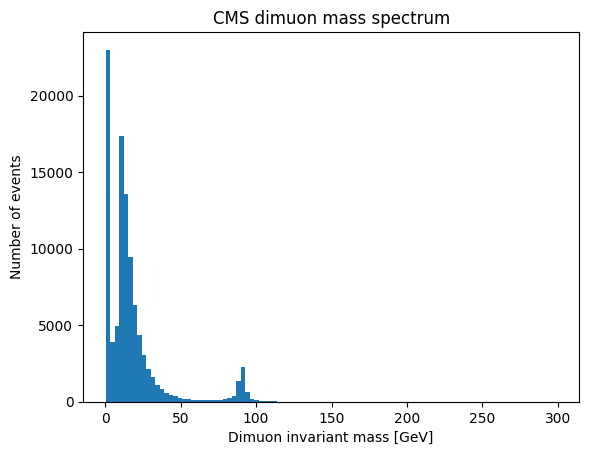

In [15]:
import matplotlib.pyplot as plt

mass = data["M"]

plt.hist(mass, bins=100)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("CMS dimuon mass spectrum")
plt.show()

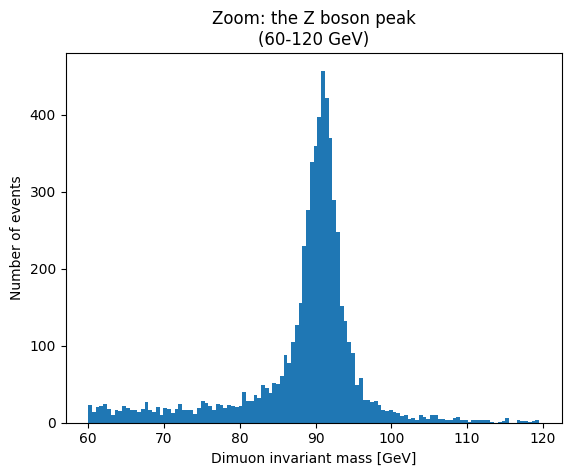

In [16]:
mas = data["M"]

z_region = mas[(mas > 60) & (mas < 120)]

plt.hist(z_region, bins=120)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Zoom: the Z boson peak\n(60-120 GeV)")
plt.show()

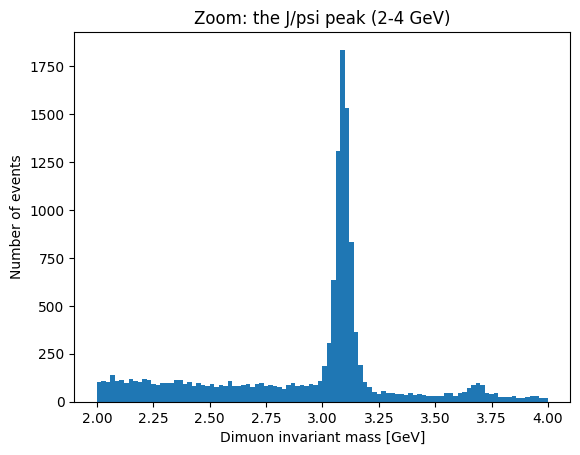

In [17]:
jpsi_region = mass[(mass > 2) & (mass < 4)]

plt.hist(jpsi_region, bins=100)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Zoom: the J/psi peak (2-4 GeV)")
plt.show()

In [18]:
import numpy as np

total_energy = data["E1"] + data["E2"]
total_px = data["px1"] + data["px2"]
total_py = data["py1"] + data["py2"]
total_pz = data["pz1"] + data["pz2"]

total_momentum_squared = total_px**2 + total_py**2 + total_pz**2

my_mass = np.sqrt(total_energy**2 - total_momentum_squared)

print("My calculated mass, first 5 values:")
print(my_mass.head())
print()
print("CMS supplied mass, first 5 values:")
print(data["M"].head())

My calculated mass, first 5 values:
0    17.492090
1    11.553492
2     9.163692
3    12.477448
4    14.315904
dtype: float64

CMS supplied mass, first 5 values:
0    17.4922
1    11.5534
2     9.1636
3    12.4774
4    14.3159
Name: M, dtype: float64


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


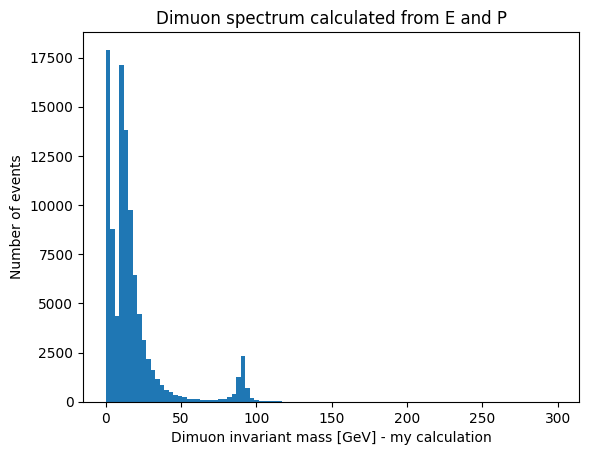

In [19]:
plt.hist(my_mass, bins=100)
plt.xlabel("Dimuon invariant mass [GeV] - my calculation")
plt.ylabel("Number of events")
plt.title("Dimuon spectrum calculated from E and P")
plt.show()

In [20]:
difference = my_mass - data ["M"]

print("Events when my calculation is NaN:", my_mass.isna().sum())
print("Average difference from CMS:", difference.abs().mean(), "GeV")
print("Largest difference from CMS:", difference.abs().max(), "GeV")

Events when my calculation is NaN: 1
Average difference from CMS: 0.0003684252935262137 GeV
Largest difference from CMS: 0.8291972087026647 GeV


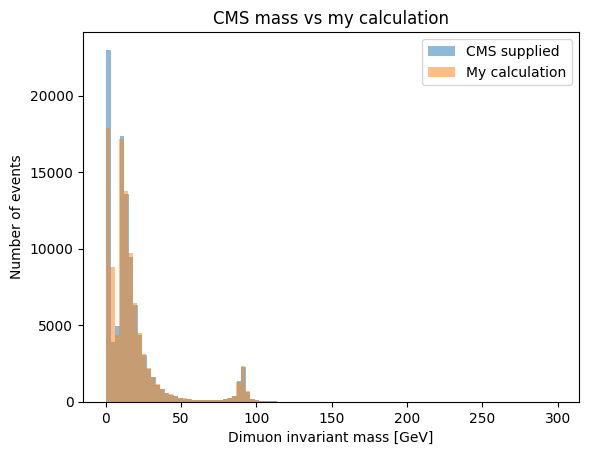

In [21]:
plt.hist(data["M"], bins=100, alpha=0.5, label="CMS supplied")
plt.hist(my_mass, bins=100, alpha=0.5, label="My calculation")
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("CMS mass vs my calculation")
plt.legend()
plt.show()

In [22]:
difference = my_mass - data["M"]

print("Events differing by more than 0.01 GeV:", (difference.abs() > 0.01).sum())
print("CMS masses below 3 GeV:", (data["M"] < 3).sum())
print("My masses below 3 GeV:", (my_mass < 3).sum())

Events differing by more than 0.01 GeV: 197
CMS masses below 3 GeV: 15461
My masses below 3 GeV: 15458


Number of outlier events: 197
Smallest CMS mass among them: 0.3007
Largest CMS mass among them: 25.8176



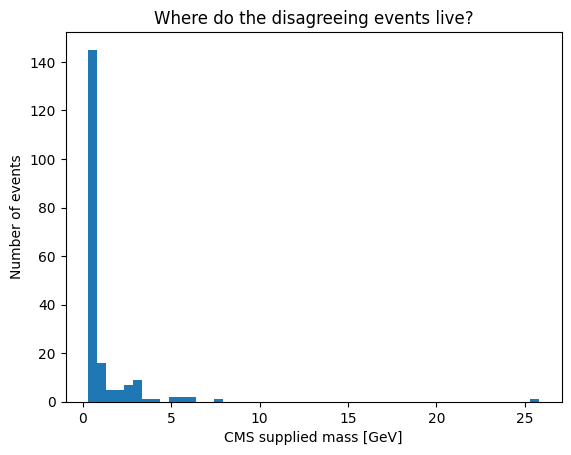

In [23]:
outlier_mask = difference.abs() > 0.01

outlier_masses = data.loc[outlier_mask, "M"]

print("Number of outlier events:", len(outlier_masses))
print("Smallest CMS mass among them:", outlier_masses.min())
print("Largest CMS mass among them:", outlier_masses.max())
print()

plt.hist(outlier_masses, bins=50)
plt.xlabel("CMS supplied mass [GeV]")
plt.ylabel("Number of events")
plt.title("Where do the disagreeing events live?")
plt.show()

Number of outlier events: 197
Smallest CMS mass among them: 0.3007
Largest CMS mass among them: 25.8176



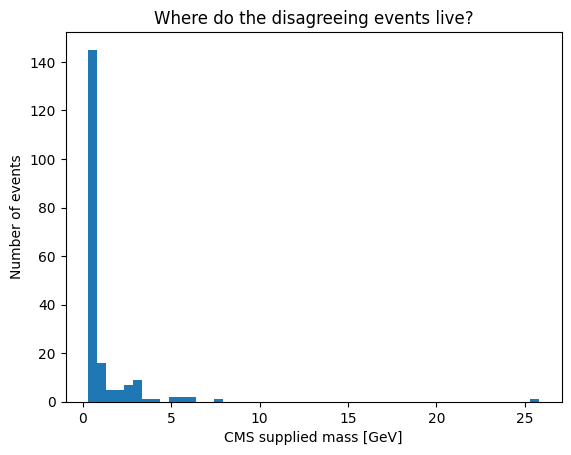

In [24]:
outlier_mask = difference.abs() > 0.01

outlier_masses = data.loc[outlier_mask, "M"]

print("Number of outlier events:", len(outlier_masses))
print("Smallest CMS mass among them:", outlier_masses.min())
print("Largest CMS mass among them:", outlier_masses.max())
print()

plt.hist(outlier_masses, bins=50)
plt.xlabel("CMS supplied mass [GeV]")
plt.ylabel("Number of events")
plt.title("Where do the disagreeing events live?")
plt.show()

In [25]:
bins = [0, 1, 3, 10, 30, 100, 300]
mass_range = pd.cut(data["M"], bins=bins)

summary = pd.DataFrame({
    "events": data.groupby(mass_range, observed=True).size(),
    "outliers": data[outlier_mask].groupby(mass_range[outlier_mask], observed=True).size()
}).fillna(0)

summary["outlier_percent"] = 100 * summary["outliers"] / summary["events"]
print(summary)

            events  outliers  outlier_percent
M                                            
(0, 1]        4626     153.0         3.307393
(1, 3]       10835      26.0         0.239963
(3, 10]      21782      17.0         0.078046
(10, 30]     50739       1.0         0.001971
(30, 100]    11747       0.0         0.000000
(100, 300]     271       0.0         0.000000


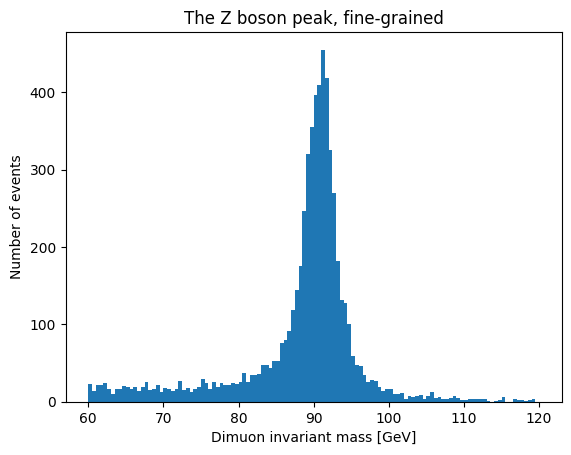

Events in the Z region: 6124
First 10 bin counts: [23. 14. 22. 22. 24. 17. 10. 17. 17. 20.]
Bin width (GeV): 0.5


In [26]:
z_data = data["M"][(data["M"] > 60) & (data["M"] < 120)]

counts, bin_edges, _ = plt.hist(z_data, bins=120, range=(60, 120))

plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("The Z boson peak, fine-grained")
plt.show()

print("Events in the Z region:", len(z_data))
print("First 10 bin counts:", counts[:10])
print("Bin width (GeV):", bin_edges[1] - bin_edges[0])

In [27]:
import numpy as np
from scipy.optimize import curve_fit

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

def breit_wigner_with_background(m, mass, width, height, background, slope):
    half = width / 2
    peak = height * half**2 / ((m - mass)**2 + half**2)
    background_shape = background + slope * (m - 90)
    return peak + background_shape

In [28]:
initial_guesses = [91, 3, 400, 20, -0.5]

best_values, covariance = curve_fit(
    breit_wigner_with_background,
    bin_centers,
    counts,
    p0=initial_guesses,
    sigma=np.sqrt(counts + 1),
    absolute_sigma=True
)

z_mass = best_values[0]
z_mass_error = np.sqrt(covariance[0, 0])

print("Measured Z mass:", round(z_mass, 3), "+/-", round(z_mass_error, 3), "GeV")
print("Measured Z width:", round(best_values[1], 3), "GeV")
print("Background height at 90 GeV:", round(best_values[3], 1), "events")

Measured Z mass: 90.76 +/- 0.038 GeV
Measured Z width: 3.693 GeV
Background height at 90 GeV: 6.0 events


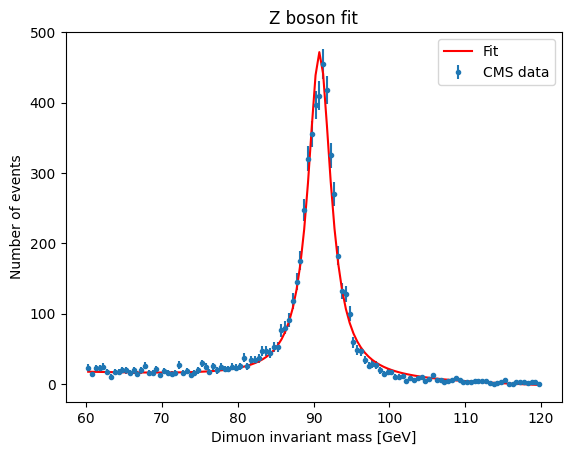

Chi-squared / degrees of freedom: 207.6 / 115
Fit window 70-110 GeV: mass = 90.777 +/- 0.038
Fit window 75-105 GeV: mass = 90.808 +/- 0.039
Fit window 80-100 GeV: mass = 90.846 +/- 0.041


In [29]:
fit_curve = breit_wigner_with_background(bin_centers, *best_values)

plt.errorbar(bin_centers, counts, yerr=np.sqrt(counts + 1), fmt="o", markersize=3, label="CMS data")
plt.plot(bin_centers, fit_curve, "r-", label="Fit")
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Z boson fit")
plt.legend()
plt.show()

chi2 = np.sum(((counts - fit_curve) / np.sqrt(counts + 1))**2)
dof = len(counts) - len(best_values)
print("Chi-squared / degrees of freedom:", round(chi2, 1), "/", dof)

for low, high in [(70, 110), (75, 105), (80, 100)]:
    mask = (bin_centers > low) & (bin_centers < high)
    vals, cov = curve_fit(
        breit_wigner_with_background,
        bin_centers[mask], counts[mask],
        p0=initial_guesses,
        sigma=np.sqrt(counts[mask] + 1),
        absolute_sigma=True
    )
    print(f"Fit window {low}-{high} GeV: mass = {vals[0]:.3f} +/- {np.sqrt(cov[0,0]):.3f}")

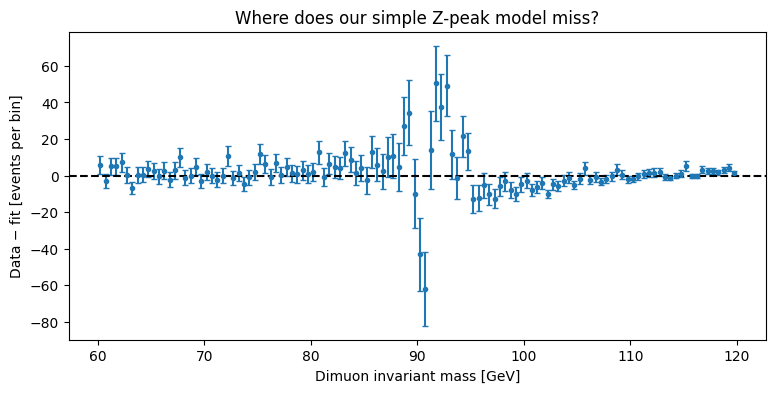

In [30]:
# Predictions from the original 60–120 GeV fit
fit_prediction = breit_wigner_with_background(
    bin_centers, *best_values
)

# Keep the same approximate uncertainties used in that fit
count_errors = np.sqrt(counts + 1)

# Difference between each observed count and the model prediction
residuals = counts - fit_prediction

plt.figure(figsize=(9, 4))

plt.errorbar(
    bin_centers,
    residuals,
    yerr=count_errors,
    fmt="o",
    markersize=3,
    capsize=2
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Data − fit [events per bin]")
plt.title("Where does our simple Z-peak model miss?")
plt.show()

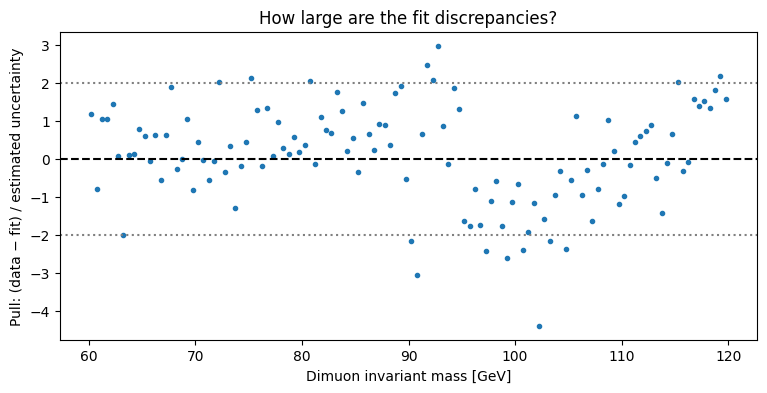

Bins with |pull| > 2: 16
Total bins: 120
Smallest predicted bin count: -1.6


In [31]:
# Use the same approximate errors as our original fit
pulls = residuals / count_errors

plt.figure(figsize=(9, 4))

plt.plot(bin_centers, pulls, "o", markersize=3)

plt.axhline(0, color="black", linestyle="--")
plt.axhline(2, color="gray", linestyle=":")
plt.axhline(-2, color="gray", linestyle=":")

plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Pull: (data − fit) / estimated uncertainty")
plt.title("How large are the fit discrepancies?")
plt.show()

print("Bins with |pull| > 2:", int((np.abs(pulls) > 2).sum()))
print("Total bins:", len(pulls))
print("Smallest predicted bin count:", round(fit_prediction.min(), 2))

Fitted peak center: 90.737 +/- 0.037 GeV
Approximate chi-squared / degrees of freedom: 248.7 / 115
Smallest predicted bin count: 2.20


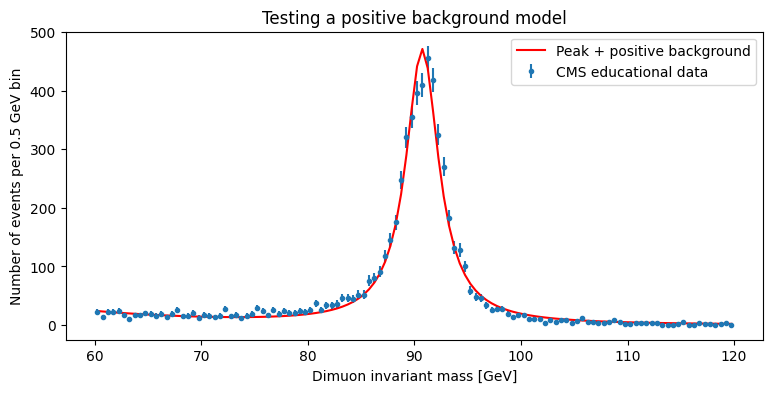

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def peak_with_positive_background(
    m, mass, width, height, background, decay
):
    half = width / 2

    peak = height * half**2 / (
        (m - mass)**2 + half**2
    )

    background_shape = background * np.exp(
        -decay * (m - 90)
    )

    return peak + background_shape


positive_values, positive_covariance = curve_fit(
    peak_with_positive_background,
    bin_centers,
    counts,
    p0=[90.8, 3.7, 450, 6, 0.05],
    bounds=(
        [85, 0.1, 0, 0, -0.2],
        [97, 20, np.inf, np.inf, 0.2]
    ),
    sigma=count_errors,
    absolute_sigma=True,
    maxfev=20000
)

positive_prediction = peak_with_positive_background(
    bin_centers, *positive_values
)

positive_pulls = (
    counts - positive_prediction
) / count_errors

positive_chi2 = np.sum(positive_pulls**2)
positive_dof = len(counts) - len(positive_values)

print(
    "Fitted peak center:",
    f"{positive_values[0]:.3f} +/- "
    f"{np.sqrt(positive_covariance[0, 0]):.3f} GeV"
)
print(
    "Approximate chi-squared / degrees of freedom:",
    f"{positive_chi2:.1f} / {positive_dof}"
)
print(
    "Smallest predicted bin count:",
    f"{positive_prediction.min():.2f}"
)

plt.figure(figsize=(9, 4))

plt.errorbar(
    bin_centers, counts,
    yerr=count_errors,
    fmt="o", markersize=3,
    label="CMS educational data"
)

plt.plot(
    bin_centers, positive_prediction,
    color="red",
    label="Peak + positive background"
)

plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events per 0.5 GeV bin")
plt.title("Testing a positive background model")
plt.legend()
plt.show()

In [33]:
from scipy.optimize import least_squares
from scipy.special import xlogy

def poisson_residuals(parameters):
    predicted = peak_with_positive_background(
        bin_centers, *parameters
    )

    # Numerical protection against taking log(0)
    predicted = np.maximum(predicted, 1e-12)

    # Each bin's contribution to the Poisson deviance.
    # xlogy handles bins with zero observed events.
    contribution = 2 * (
        predicted - counts
        + xlogy(counts, counts / predicted)
    )

    # Guard against tiny negative values from numerical rounding
    contribution = np.maximum(contribution, 0)

    return (
        np.sign(counts - predicted)
        * np.sqrt(contribution)
    )


poisson_fit = least_squares(
    poisson_residuals,
    x0=positive_values,
    bounds=(
        [85, 0.1, 0, 0, -0.2],
        [97, 20, np.inf, np.inf, 0.2]
    ),
    x_scale="jac",
    max_nfev=10000
)

poisson_values = poisson_fit.x

poisson_prediction = peak_with_positive_background(
    bin_centers, *poisson_values
)

deviance = np.sum(poisson_fit.fun**2)
dof = len(counts) - len(poisson_values)

print("Optimizer converged:", poisson_fit.success)
print("Optimizer message:", poisson_fit.message)
print(f"Fitted peak center: {poisson_values[0]:.3f} GeV")
print(f"Fitted width parameter: {poisson_values[1]:.3f} GeV")
print(f"Poisson deviance / degrees of freedom: {deviance:.1f} / {dof}")

Optimizer converged: True
Optimizer message: `ftol` termination condition is satisfied.
Fitted peak center: 90.756 GeV
Fitted width parameter: 3.848 GeV
Poisson deviance / degrees of freedom: 227.7 / 115


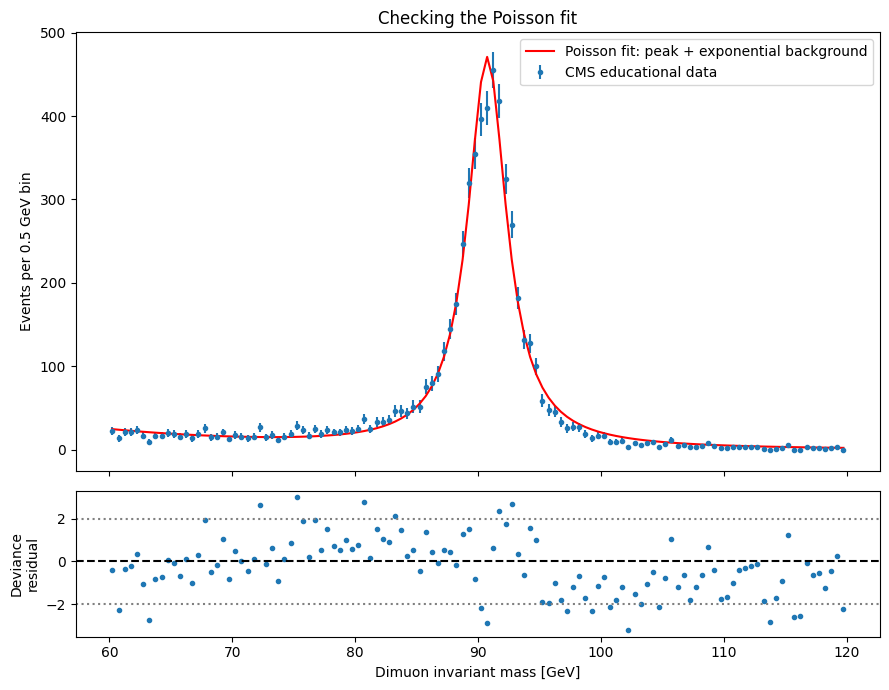

In [34]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Top panel: data and fitted predictions
axes[0].errorbar(
    bin_centers,
    counts,
    yerr=count_errors,
    fmt="o",
    markersize=3,
    label="CMS educational data"
)

axes[0].plot(
    bin_centers,
    poisson_prediction,
    color="red",
    label="Poisson fit: peak + exponential background"
)

axes[0].set_ylabel("Events per 0.5 GeV bin")
axes[0].set_title("Checking the Poisson fit")
axes[0].legend()

# Bottom panel: signed Poisson-deviance residuals
deviance_residuals = poisson_residuals(poisson_values)

axes[1].plot(
    bin_centers,
    deviance_residuals,
    "o",
    markersize=3
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].axhline(2, color="gray", linestyle=":")
axes[1].axhline(-2, color="gray", linestyle=":")

axes[1].set_xlabel("Dimuon invariant mass [GeV]")
axes[1].set_ylabel("Deviance\nresidual")

plt.tight_layout()
plt.show()

In [35]:
from scipy.special import voigt_profile

def voigt_with_background(
    m, mass, width, sigma, height, background, decay
):
    # SciPy uses the Lorentzian HALF-width
    gamma = width / 2

    # Normalize the peak so "height" means its central height
    peak = height * (
        voigt_profile(m - mass, sigma, gamma)
        / voigt_profile(0, sigma, gamma)
    )

    background_shape = background * np.exp(
        -decay * (m - 90)
    )

    return peak + background_shape


def voigt_residuals(parameters):
    predicted = voigt_with_background(
        bin_centers, *parameters
    )
    predicted = np.maximum(predicted, 1e-12)

    contribution = 2 * (
        predicted - counts
        + xlogy(counts, counts / predicted)
    )

    return (
        np.sign(counts - predicted)
        * np.sqrt(np.maximum(contribution, 0))
    )


voigt_fit = least_squares(
    voigt_residuals,
    x0=[
        poisson_values[0],  # previous fitted center
        2.5,               # starting Lorentzian width
        1.0,               # starting Gaussian spread
        poisson_values[2], # previous peak height
        poisson_values[3], # previous background height
        poisson_values[4]  # previous background decay
    ],
    bounds=(
        [85, 0.1, 0.01, 0, 0, -0.2],
        [97, 20, 10, np.inf, np.inf, 0.2]
    ),
    x_scale="jac",
    max_nfev=10000
)

voigt_values = voigt_fit.x
voigt_deviance = np.sum(voigt_fit.fun**2)

print("Optimizer converged:", voigt_fit.success)
print(f"Fitted peak center: {voigt_values[0]:.3f} GeV")
print(f"Lorentzian width parameter: {voigt_values[1]:.3f} GeV")
print(f"Gaussian spread parameter: {voigt_values[2]:.3f} GeV")

print(
    "Previous model deviance:",
    f"{np.sum(poisson_fit.fun**2):.1f}",
    "with 5 fitted parameters"
)
print(
    "Voigt model deviance:",
    f"{voigt_deviance:.1f}",
    "with 6 fitted parameters"
)

Optimizer converged: True
Fitted peak center: 90.742 GeV
Lorentzian width parameter: 3.104 GeV
Gaussian spread parameter: 1.036 GeV
Previous model deviance: 227.7 with 5 fitted parameters
Voigt model deviance: 196.9 with 6 fitted parameters


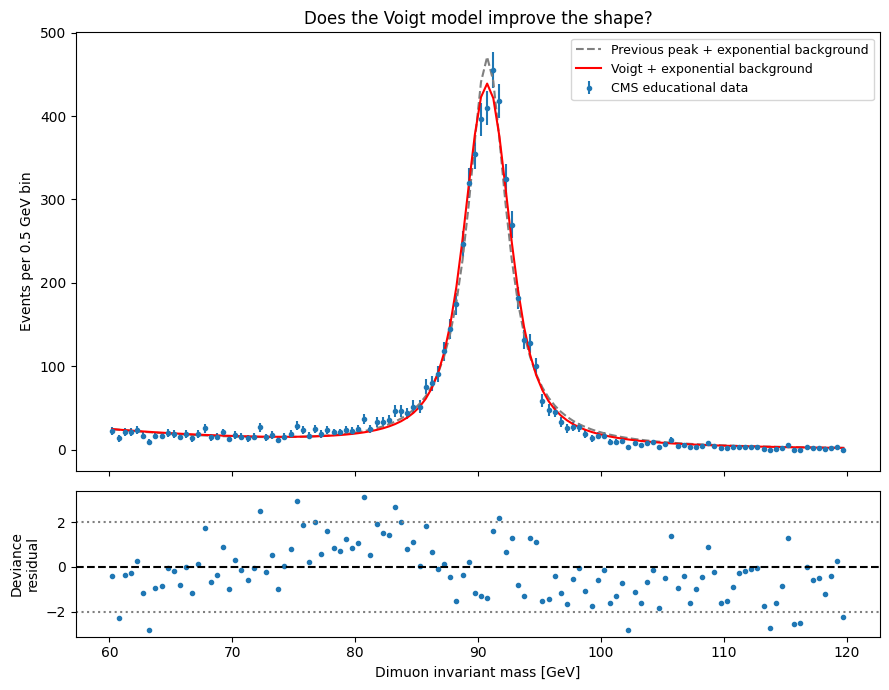

In [36]:
voigt_prediction = voigt_with_background(
    bin_centers, *voigt_values
)

voigt_deviance_residuals = voigt_residuals(voigt_values)

fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Top: data and both fitted models
axes[0].errorbar(
    bin_centers,
    counts,
    yerr=count_errors,
    fmt="o",
    markersize=3,
    label="CMS educational data"
)

axes[0].plot(
    bin_centers,
    poisson_prediction,
    "--",
    color="gray",
    label="Previous peak + exponential background"
)

axes[0].plot(
    bin_centers,
    voigt_prediction,
    color="red",
    label="Voigt + exponential background"
)

axes[0].set_ylabel("Events per 0.5 GeV bin")
axes[0].set_title("Does the Voigt model improve the shape?")
axes[0].legend(fontsize=9)

# Bottom: residuals for the Voigt model
axes[1].plot(
    bin_centers,
    voigt_deviance_residuals,
    "o",
    markersize=3
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].axhline(2, color="gray", linestyle=":")
axes[1].axhline(-2, color="gray", linestyle=":")

axes[1].set_xlabel("Dimuon invariant mass [GeV]")
axes[1].set_ylabel("Deviance\nresidual")

plt.tight_layout()
plt.show()

In [37]:
# Sample 16 carefully chosen positions inside each bin
nodes, weights = np.polynomial.legendre.leggauss(16)

half_widths = np.diff(bin_edges) / 2
sample_masses = (
    bin_centers[:, None]
    + half_widths[:, None] * nodes[None, :]
)

# The original model's height is in events per 0.5 GeV bin
reference_width = 0.5


def integrated_voigt_counts(parameters):
    sampled_model = voigt_with_background(
        sample_masses, *parameters
    )

    return (
        half_widths / reference_width
        * np.sum(sampled_model * weights[None, :], axis=1)
    )


def integrated_residuals(parameters):
    predicted = np.maximum(
        integrated_voigt_counts(parameters), 1e-12
    )

    contribution = 2 * (
        predicted - counts
        + xlogy(counts, counts / predicted)
    )

    return (
        np.sign(counts - predicted)
        * np.sqrt(np.maximum(contribution, 0))
    )


integrated_fit = least_squares(
    integrated_residuals,
    x0=voigt_values,
    bounds=(
        [85, 0.1, 0.01, 0, 0, -0.2],
        [97, 20, 10, np.inf, np.inf, 0.2]
    ),
    x_scale="jac",
    max_nfev=10000
)

integrated_values = integrated_fit.x
integrated_deviance = np.sum(integrated_fit.fun**2)

print("Optimizer converged:", integrated_fit.success)
print(f"Bin-center fit center: {voigt_values[0]:.5f} GeV")
print(f"Bin-integrated fit center: {integrated_values[0]:.5f} GeV")
print(
    "Change in fitted center:",
    f"{integrated_values[0] - voigt_values[0]:+.5f} GeV"
)
print(f"Bin-integrated deviance: {integrated_deviance:.2f}")

Optimizer converged: True
Bin-center fit center: 90.74188 GeV
Bin-integrated fit center: 90.74188 GeV
Change in fitted center: +0.00000 GeV
Bin-integrated deviance: 196.85


In [38]:
# Reproducible simulated experiments
rng = np.random.default_rng(42)

# Expected bin counts from our fitted model
expected_counts = integrated_voigt_counts(integrated_values)

lower_bounds = [85, 0.1, 0.01, 0, 0, -0.2]
upper_bounds = [97, 20, 10, np.inf, np.inf, 0.2]


def toy_residuals(parameters, observed_counts):
    predicted = np.maximum(
        integrated_voigt_counts(parameters), 1e-12
    )

    contribution = 2 * (
        predicted - observed_counts
        + xlogy(observed_counts, observed_counts / predicted)
    )

    return (
        np.sign(observed_counts - predicted)
        * np.sqrt(np.maximum(contribution, 0))
    )


n_toys = 200
toy_centers = []
failed_fits = 0
boundary_fits = 0

for i in range(n_toys):
    # Generate a new simulated histogram, not new CMS data
    toy_counts = rng.poisson(expected_counts)

    result = least_squares(
        toy_residuals,
        x0=integrated_values,
        args=(toy_counts,),
        bounds=(lower_bounds, upper_bounds),
        x_scale="jac",
        max_nfev=3000
    )

    if result.success:
        toy_centers.append(result.x[0])

        if np.any(result.active_mask != 0):
            boundary_fits += 1
    else:
        failed_fits += 1

    if (i + 1) % 50 == 0:
        print(f"Completed {i + 1}/{n_toys} simulated experiments")

toy_centers = np.array(toy_centers)

print()
print("Successful fits:", len(toy_centers))
print("Failed fits:", failed_fits)
print("Successful fits at a parameter bound:", boundary_fits)

if len(toy_centers) >= 2:
    statistical_spread = np.std(toy_centers, ddof=1)
    mean_shift = np.mean(toy_centers) - integrated_values[0]

    print(f"Spread of fitted centers: {statistical_spread:.4f} GeV")
    print(f"Mean shift from generating center: {mean_shift:+.4f} GeV")

Completed 50/200 simulated experiments
Completed 100/200 simulated experiments
Completed 150/200 simulated experiments
Completed 200/200 simulated experiments

Successful fits: 200
Failed fits: 0
Successful fits at a parameter bound: 0
Spread of fitted centers: 0.0395 GeV
Mean shift from generating center: -0.0016 GeV


A bin-integrated Voigt profile plus an exponential background gives a fitted dimuon peak center of 90.742 GeV. A parametric bootstrap with 200 simulated experiments gives an estimated statistical spread of 0.040 GeV. All simulated fits converged without reaching parameter bounds. Structured residuals remain in the real-data fit, so this is a model-dependent peak-center estimate, not a precision determination of the Z boson mass.

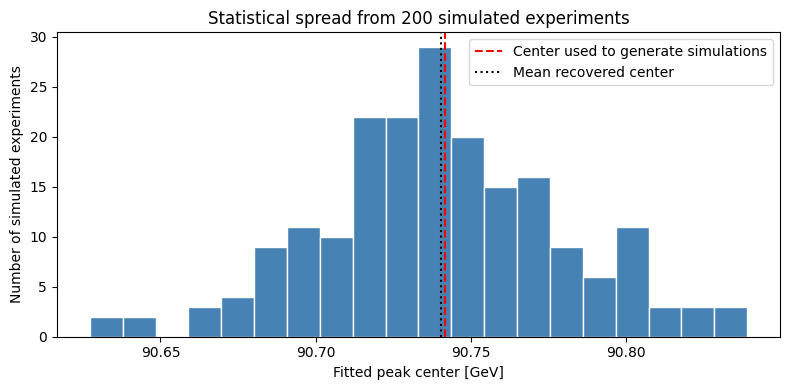

In [39]:
plt.figure(figsize=(8, 4))

plt.hist(
    toy_centers,
    bins=20,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    integrated_values[0],
    color="red",
    linestyle="--",
    label="Center used to generate simulations"
)

plt.axvline(
    np.mean(toy_centers),
    color="black",
    linestyle=":",
    label="Mean recovered center"
)

plt.xlabel("Fitted peak center [GeV]")
plt.ylabel("Number of simulated experiments")
plt.title("Statistical spread from 200 simulated experiments")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
windows = [
    (60, 120),
    (70, 110),
    (75, 105),
    (80, 100)
]

window_results = []


def window_residuals(parameters, mask):
    predicted = np.maximum(
        integrated_voigt_counts(parameters)[mask],
        1e-12
    )
    observed = counts[mask]

    contribution = 2 * (
        predicted - observed
        + xlogy(observed, observed / predicted)
    )

    return (
        np.sign(observed - predicted)
        * np.sqrt(np.maximum(contribution, 0))
    )


for low, high in windows:
    # Include only bins entirely inside the chosen window
    mask = (
        (bin_edges[:-1] >= low)
        & (bin_edges[1:] <= high)
    )

    result = least_squares(
        window_residuals,
        x0=integrated_values.copy(),
        args=(mask,),
        bounds=(lower_bounds, upper_bounds),
        x_scale="jac",
        max_nfev=10000
    )

    window_results.append({
        "window_GeV": f"{low}–{high}",
        "center_GeV": result.x[0],
        "shift_from_full_GeV": (
            result.x[0] - integrated_values[0]
        ),
        "deviance": np.sum(result.fun**2),
        "dof": int(mask.sum()) - len(result.x),
        "converged": result.success,
        "at_bound": bool(np.any(result.active_mask != 0))
    })

window_table = pd.DataFrame(window_results)

print(window_table.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}"
))

window_GeV  center_GeV  shift_from_full_GeV  deviance  dof  converged  at_bound
    60–120     90.7419              -0.0000  196.8524  114       True     False
    70–110     90.7595               0.0177  115.0031   74       True     False
    75–105     90.7788               0.0369   70.9312   54       True     False
    80–100     90.8136               0.0718   38.4218   34       True     False


## Conclusion: Z-region peak fitting

I fitted the CMS educational dimuon spectrum over 60–120 GeV
using a bin-integrated Voigt profile plus an exponential
background, with a binned Poisson likelihood.

The full-window fitted peak center was 90.742 GeV. A parametric
bootstrap with 200 simulated experiments gave a statistical
spread of 0.040 GeV. All 200 simulated fits converged without
reaching parameter bounds.

Integrating the model across each bin produced no change in
the fitted center at the five-decimal-place precision displayed.

However, structured residuals remained. Changing the fit window
shifted the center upward, reaching 90.814 GeV for 80–100 GeV:
a shift of 0.072 GeV from the full-window result. All tested
window fits converged without reaching parameter bounds.

Therefore, 0.040 GeV describes statistical variation conditional
on the fitted model; it is not a complete measurement uncertainty.
The window study is a sensitivity check, not a complete systematic
uncertainty evaluation.

This analysis estimates a model-dependent dimuon peak center.
It is not a precision measurement of the Z boson mass, natural
width, or detector resolution.